Importing the libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Making sure the program runs well

In [231]:
print("Hello World")

Hello World


Loading the CSV file and viewing 5 random rows for data exploration

We have columns derived from other columns, and we also have duplicated columns

In [232]:
df=pd.read_csv('titanic.csv')
df.head().sample(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False


891 rows and 15 cols and theres is missing values 

In [233]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


now we notice outlier in fare col

In [234]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


We need to check the unique values in each column.
We want to find any mistakes or spelling errors, like writing 'treu' instead of 'True'.

In [235]:
def show_unique(df):
    for col in df.columns:
        uniques = df[col].unique()
        print(f"{col}: {uniques}")
show_unique(df)

survived: [0 1]
pclass: [3 1 2]
sex: <StringArray>
['male', 'female']
Length: 2, dtype: str
age: [22.   38.   26.   35.     nan 54.    2.   27.   14.    4.   58.   20.
 39.   55.   31.   34.   15.   28.    8.   19.   40.   66.   42.   21.
 18.    3.    7.   49.   29.   65.   28.5   5.   11.   45.   17.   32.
 16.   25.    0.83 30.   33.   23.   24.   46.   59.   71.   37.   47.
 14.5  70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.
 56.   50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.
 60.   10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.
  0.67 30.5   0.42 34.5  74.  ]
sibsp: [1 0 3 4 2 5 8]
parch: [0 1 2 5 3 4 6]
fare: [  7.25    71.2833   7.925   53.1      8.05     8.4583  51.8625  21.075
  11.1333  30.0708  16.7     26.55    31.275    7.8542  16.      29.125
  13.      18.       7.225   26.       8.0292  35.5     31.3875 263.
   7.8792   7.8958  27.7208 146.5208   7.75    10.5     82.1708  52.
   7.2292  11.2417   9.475   21.      41

alive and servived col have same value but we want to check if both cols are equal

so we mapped alive to numeric like servived to compare

In [236]:
df['alive_numeric']=df['alive'].map({'yes':1,'no':0})


In [237]:
df.columns


Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone', 'alive_numeric'],
      dtype='str')

we notice that they are equal so we can drop alive and alive numeric

In [238]:
areEqual=(df['alive_numeric']==df['survived']).all()
print(f"are the two columns equal? {areEqual}")

are the two columns equal? True


In [239]:
df=df.drop(columns=['alive','alive_numeric'],errors='ignore')
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alone'],
      dtype='str')

like survived and alive there's class and pclass so we did the same

In [240]:
df['class_numeric']=df['class'].map({'First':1,'Second':2,'Third':3})
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alone', 'class_numeric'],
      dtype='str')

and they're equal so we can dropping it

In [241]:
areEqualp=(df['class_numeric']==df['pclass']).all()
print(f"are the two columns equal? {areEqualp}")

are the two columns equal? True


In [242]:
df=df.drop(columns=['class_numeric','class'],errors='ignore')
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'who', 'adult_male', 'deck', 'embark_town', 'alone'],
      dtype='str')

also like above we want to compare emark town and embark cols

In [243]:
df['embark_town_code']=df['embark_town'].map({
    'Queenstown':'Q',
    'Cherbourg':'C',
    'Southampton':'S'
})

but suddenly they're not equal ..

In [244]:
areEqualCode=(df['embark_town_code']==df['embarked']).all()

print(f"are the two columns equal? {areEqualCode}")

are the two columns equal? False


I thought the values were conflicting. When I checked, the unequal values were NaN. I wondered why NaN does not equal NaN. Then, I learned that NaN values are never equal. This is because they come from different math errors, like dividing by zero. According to the IEEE standard, any comparison with NaN is always false.

In [245]:
different=df[df['embark_town_code'] != df['embarked']]
print(different[['embarked','embark_town_code','embark_town']])

    embarked embark_town_code embark_town
61       NaN              NaN         NaN
829      NaN              NaN         NaN


then i dropped the col

In [246]:
df=df.drop(columns=['embark_town_code','embark_town'],errors='ignore')
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'who', 'adult_male', 'deck', 'alone'],
      dtype='str')

i filled the NaN values with mode()[0]

In [247]:
most_common=df['embarked'].mode()[0]
df['embarked']=df['embarked'].fillna(most_common)
print(df['embarked'].isna().sum())

0


then i checked the cols and i notice that  age and deck have NaN values 

In [248]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   sex         891 non-null    str    
 3   age         714 non-null    float64
 4   sibsp       891 non-null    int64  
 5   parch       891 non-null    int64  
 6   fare        891 non-null    float64
 7   embarked    891 non-null    str    
 8   who         891 non-null    str    
 9   adult_male  891 non-null    bool   
 10  deck        203 non-null    str    
 11  alone       891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(4)
memory usage: 71.5 KB


Then, I started fixing the missing values in the age column.
other columns are derived from age and they are full, I needed to calculate the missing ages using who and sex columns. For example, finding the age for female children.

In [249]:
print(df.groupby(['who', 'sex'])['age'].median())

who    sex   
child  female     6.0
       male       4.0
man    male      30.0
woman  female    30.0
Name: age, dtype: float64


 I tried using both mean and median. Because there are big differences in ages (outliers), the median was better than the mean.

In [250]:
print(df.groupby(['who', 'sex'])['age'].mean())

who    sex   
child  female     7.209302
       male       5.466750
man    male      33.173123
woman  female    32.000000
Name: age, dtype: float64


In [251]:
df['age']=df.groupby(['who', 'sex'])['age'].transform(lambda x: x.fillna(x.median()))

In [252]:
print(df['age'].isna().sum())

0


and now age have no null value and still the deck col have so we want to handel it

In [253]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   sex         891 non-null    str    
 3   age         891 non-null    float64
 4   sibsp       891 non-null    int64  
 5   parch       891 non-null    int64  
 6   fare        891 non-null    float64
 7   embarked    891 non-null    str    
 8   who         891 non-null    str    
 9   adult_male  891 non-null    bool   
 10  deck        203 non-null    str    
 11  alone       891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(4)
memory usage: 71.5 KB


We checked the unique values in the deck col to understand what it means and what this col is about

In [254]:
print(df['deck'].unique())


<StringArray>
[nan, 'C', 'E', 'G', 'D', 'A', 'B', 'F']
Length: 8, dtype: str


becasue its have so much null values

In [255]:
deck_not_null = df[df['deck'].notna()].copy()

deck_not_null['deck_numeric'] = deck_not_null['deck'].astype('category').cat.codes

col_compare = ['survived', 'pclass', 'age', 'fare', 'sibsp', 'parch', 'deck_numeric']
correlation_matrix = deck_not_null[col_compare].corr()



In [256]:
not_null_count = deck_not_null['deck'].notna()sum()
print(f"Number of non-null rows in deck column: {not_null_count}").

SyntaxError: invalid syntax (1977825385.py, line 1)

In [ ]:

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap (Filtered Deck Data Only)', fontsize=14)
plt.show()

We can see a strong positive correlation ($0.62$) between deck_numeric and pclass. This means that higher passenger classes (like First Class) were located on higher deck levels.  

there's relation between pclass and deck so we can say its usifull but becase alot of null values we cannot depends on it so i decided to remove it

so We should drop the deck column keeping this column or filling missing values can lead to inaccurate results, so removing it is the best choice for our analysis.

In [ ]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'who', 'adult_male', 'deck', 'alone'],
      dtype='str')

In [ ]:
df = df.drop(columns=['deck', 'deck_numeric'], errors='ignore')
print(df.columns)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   sex         891 non-null    str    
 3   age         891 non-null    float64
 4   sibsp       891 non-null    int64  
 5   parch       891 non-null    int64  
 6   fare        891 non-null    float64
 7   embarked    891 non-null    str    
 8   who         891 non-null    str    
 9   adult_male  891 non-null    bool   
 10  deck        203 non-null    str    
 11  alone       891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(4)
memory usage: 71.5 KB


Now that all missing values are handled the dataset is complete

We need to check for duplicate rows in the data

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 113


In [ ]:
df.drop_duplicates(inplace=True)
print("Number of rows after removing duplicates:", df.shape[0])

Number of rows after removing duplicates: 778


In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 778 entries, 0 to 890
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    778 non-null    int64  
 1   pclass      778 non-null    int64  
 2   sex         778 non-null    str    
 3   age         778 non-null    float64
 4   sibsp       778 non-null    int64  
 5   parch       778 non-null    int64  
 6   fare        778 non-null    float64
 7   embarked    778 non-null    str    
 8   who         778 non-null    str    
 9   adult_male  778 non-null    bool   
 10  deck        202 non-null    str    
 11  alone       778 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(4)
memory usage: 68.4 KB


In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,778.000000,778.000000,778.000000,778.000000,778.000000,778.000000
mean,0.415167,2.237789,29.886144,0.525707,0.419023,34.910352
std,0.493068,0.855754,13.776700,0.988991,0.839346,52.311087
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.250000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,30.000000,0.000000,0.000000,16.050000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.375000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


we notice that there's outlier in fare 

i make a chart to see from were the outleir started

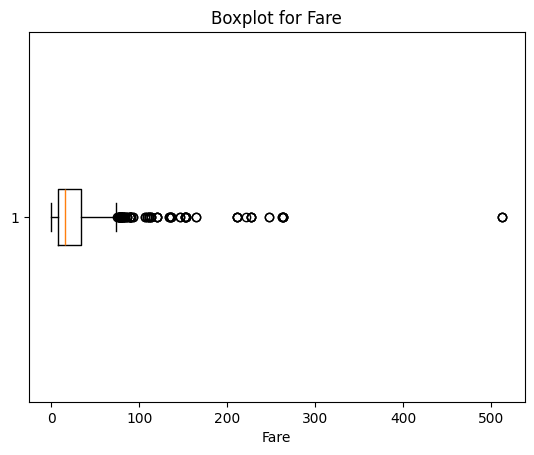

In [ ]:
# outlier
plt.Figure(figsize=(8,4))
plt.boxplot(df['fare'],vert=False)
plt.title('Boxplot for Fare')
plt.xlabel('Fare')
plt.show()

the 20 first high fare >> We noticed that some passengers share the same fare value

In [ ]:
print(df['fare'].sort_values(ascending=False).head(20))

737    512.3292
679    512.3292
258    512.3292
88     263.0000
438    263.0000
341    263.0000
27     263.0000
742    262.3750
311    262.3750
118    247.5208
299    247.5208
557    227.5250
716    227.5250
700    227.5250
380    227.5250
527    221.7792
377    211.5000
689    211.3375
730    211.3375
779    211.3375
Name: fare, dtype: float64


We filtered the data to see high fares with more than two passengers

In [ ]:
for fareValue, group in df.groupby('fare'):
    if len(group) > 2 and fareValue > 200:
        print(f"\n--- Fare = {fareValue} || num of persons = {len(group)} ---")
        display(group) 


--- Fare = 211.3375 || num of persons = 3 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
689,1,1,female,15.0,0,1,211.3375,S,child,False,B,False
730,1,1,female,29.0,0,0,211.3375,S,woman,False,B,True
779,1,1,female,43.0,0,1,211.3375,S,woman,False,B,False



--- Fare = 227.525 || num of persons = 4 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
380,1,1,female,42.0,0,0,227.525,C,woman,False,NaN,True
557,0,1,male,30.0,0,0,227.525,C,man,True,NaN,True
700,1,1,female,18.0,1,0,227.525,C,woman,False,C,False
716,1,1,female,38.0,0,0,227.525,C,woman,False,C,True



--- Fare = 263.0 || num of persons = 4 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
27,0,1,male,19.0,3,2,263.0,S,man,True,C,False
88,1,1,female,23.0,3,2,263.0,S,woman,False,C,False
341,1,1,female,24.0,3,2,263.0,S,woman,False,C,False
438,0,1,male,64.0,1,4,263.0,S,man,True,C,False



--- Fare = 512.3292 || num of persons = 3 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
258,1,1,female,35.0,0,0,512.3292,C,woman,False,NaN,True
679,1,1,male,36.0,0,1,512.3292,C,man,True,B,False
737,1,1,male,35.0,0,0,512.3292,C,man,True,B,True


i think they maybe family or friends and all of them at pclass 1 so i think its not false value

In [ ]:
df[df['fare'] > 100]['pclass'].value_counts()

pclass
1    53
Name: count, dtype: int64

All passengers who paid a fare of more than 100 are from the Pclass 1

In [ ]:
print(df.groupby('pclass')['fare'].median())

pclass
1    60.2875
2    18.7500
3     8.0500
Name: fare, dtype: float64


theres just 2 person who paid expensive fare and they're alone

In [ ]:
for fareValue, group in df.groupby('fare'):
    if len(group) == 1 and (fareValue > 100 ):
        print(f"\n--- Fare = {fareValue} || num of persons = {len(group)} ---")
        display(group)


--- Fare = 211.5 || num of persons = 1 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
377,0,1,male,27.0,0,2,211.5,C,man,True,C,False



--- Fare = 221.7792 || num of persons = 1 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
527,0,1,male,30.0,0,0,221.7792,S,man,True,C,True


In [ ]:
bins = [0, 50, 100, 200, 300, 600]
fare_counts = pd.cut(df[df['pclass'] == 1]['fare'], bins=bins).value_counts().sort_index()

print(fare_counts)

fare
(0, 50]       71
(50, 100]     85
(100, 200]    33
(200, 300]    17
(300, 600]     3
Name: count, dtype: int64


At first, when we checked the boxplot, we found some very high ticket prices that looked strange

We decided to investigate closer by checking the First Class ticket distribution.

We discovered that most passengers paid under $\$100$, but a few tickets were much higher (up to $\$500$).

After checking the data, we understood these were maybe luxury rooms or group bookings, not errors.

Therefore, we decided to keep all of these values because they are real and correct.

### For a moment, I realized we should check the deck column we deleted. So, I commented out the code that deleted it and ran the data again. I discovered that these people with high fares are all in the same deck. This means they are likely wealthy people or a family traveling together. Therefore, these high fares are not outliers; they are just expensive tickets for high-class people.

In [ ]:
# for fareValue, group in df.groupby('fare'):
#     if len(group) > 2 and (fareValue > 200 ):
#         print(f"\n--- Fare = {fareValue} || num of persons = {len(group)} ---")
#         display(group)


--- Fare = 211.3375 || num of persons = 3 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
689,1,1,female,15.0,0,1,211.3375,S,child,False,B,False
730,1,1,female,29.0,0,0,211.3375,S,woman,False,B,True
779,1,1,female,43.0,0,1,211.3375,S,woman,False,B,False



--- Fare = 227.525 || num of persons = 4 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
380,1,1,female,42.0,0,0,227.525,C,woman,False,NaN,True
557,0,1,male,30.0,0,0,227.525,C,man,True,NaN,True
700,1,1,female,18.0,1,0,227.525,C,woman,False,C,False
716,1,1,female,38.0,0,0,227.525,C,woman,False,C,True



--- Fare = 263.0 || num of persons = 4 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
27,0,1,male,19.0,3,2,263.0,S,man,True,C,False
88,1,1,female,23.0,3,2,263.0,S,woman,False,C,False
341,1,1,female,24.0,3,2,263.0,S,woman,False,C,False
438,0,1,male,64.0,1,4,263.0,S,man,True,C,False



--- Fare = 512.3292 || num of persons = 3 ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,alone
258,1,1,female,35.0,0,0,512.3292,C,woman,False,NaN,True
679,1,1,male,36.0,0,1,512.3292,C,man,True,B,False
737,1,1,male,35.0,0,0,512.3292,C,man,True,B,True


### For a moment, I realized we should check the deck column we deleted. So, I commented out the code that deleted it and ran the data again. I discovered that these people with high fares are all in the same deck. This means they are likely wealthy people or a family traveling together. Therefore, these high fares are not outliers; they are just expensive tickets for high-class people.

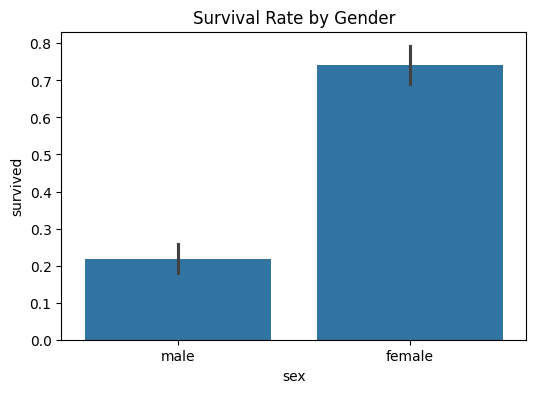

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x='sex', y='survived', data=df)
plt.title('Survival Rate by Gender')
plt.show()

We notice that the survival rate for males is lower than females. This makes sense because, in emergencies, men and fathers usually help women and their families to survive first.

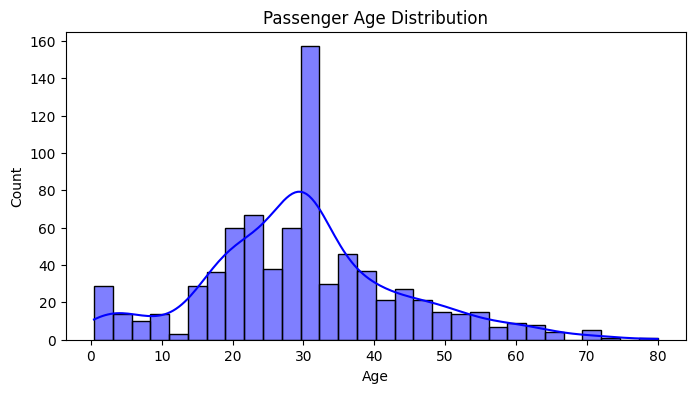

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['age'], bins=30, kde=True, color='blue')
plt.title('Passenger Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

The age distribution chart shows that most passengers were young adults between 20 and 35 years old. We can also see babies under one year old and older adults up to 80, which proves the age data is normal and correct.

In [257]:
df.to_csv('cleaned_titanic_data.csv', index=False)
print("Cleaned Titanic data saved to 'cleaned_titanic_data.csv'")

Cleaned Titanic data saved to 'cleaned_titanic_data.csv'
